# 01. Exploratory data analysis (action items S2, H1)

This notebook checks that the numbers in the proposal come from the raw data, and produces the two proposal figures (Figure 1a, Figure 1b).

The missing-BMI investigation (D1, D2) is in `02_missing_bmi.ipynb`.

The last section (H1) reports what each cleaning decision in `data/README.md` changes, by comparing results with and without it.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from statsmodels.stats.proportion import confint_proportions_2indep, proportion_confint

from src.config import ALPHA, FIGURES, N_BOOT, SEED, TABLES
from src.data import load_raw

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
RECORDED, MISSING = "#2a78d6", "#eb6834"  # colour follows the group in every figure
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11,
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 200,
})

df = load_raw()
df["bmi_missing"] = df["bmi"].isna().astype(int)

## Proposal numbers against the raw data

Each number stated in section 3 of the proposal is recomputed and compared at the precision the proposal used. The cell stops with an error if any number fails to match.

In [2]:
strokes = int(df["stroke"].sum())
miss, rec = df[df["bmi_missing"] == 1], df[df["bmi_missing"] == 0]
smoke = df["smoking_status"].value_counts()
under18 = df[df["age"] < 18]

# (item, value stated in the proposal, value from the data, decimals the proposal used)
checks = [
    ("Rows", 5110, len(df), 0),
    ("Strokes", 249, strokes, 0),
    ("Stroke rate, %", 4.87, 100 * strokes / len(df), 2),
    ("BMI missing", 201, int(df["bmi"].isna().sum()), 0),
    ("BMI missing, %", 3.9, 100 * df["bmi"].isna().mean(), 1),
    ("Stroke rate, BMI missing, %", 19.9, 100 * miss["stroke"].mean(), 1),
    ("Stroke rate, BMI recorded, %", 4.3, 100 * rec["stroke"].mean(), 1),
    ("Strokes among BMI missing", 40, int(miss["stroke"].sum()), 0),
    ("Share of strokes lost if dropped, %", 16, 100 * miss["stroke"].sum() / strokes, 0),
    ("Smoking: never smoked", 1892, int(smoke["never smoked"]), 0),
    ("Smoking: formerly smoked", 885, int(smoke["formerly smoked"]), 0),
    ("Smoking: smokes", 789, int(smoke["smokes"]), 0),
    ("Smoking: Unknown", 1544, int(smoke["Unknown"]), 0),
    ("Smoking Unknown, %", 30.2, 100 * smoke["Unknown"] / len(df), 1),
    ("Patients under 18", 856, len(under18), 0),
    ("Patients under 18, %", 16.8, 100 * len(under18) / len(df), 1),
    ("Strokes under 18", 2, int(under18["stroke"].sum()), 0),
    ("Gender 'Other'", 1, int((df["gender"] == "Other").sum()), 0),
    ("BMI > 60", 13, int((df["bmi"] > 60).sum()), 0),
    ("BMI maximum", 97.6, df["bmi"].max(), 1),
    ("BMI minimum", 10.3, df["bmi"].min(), 1),
    ("Age maximum", 82, df["age"].max(), 0),
    ("Age minimum", 0.08, df["age"].min(), 2),
    ("Glucose minimum", 55, df["avg_glucose_level"].min(), 0),
    ("Glucose maximum", 272, df["avg_glucose_level"].max(), 0),
]
check = pd.DataFrame(
    [(i, p, round(v, d), round(v, d) == p) for i, p, v, d in checks],
    columns=["item", "proposal", "reproduced", "match"],
)
check.to_csv(TABLES / "eda_proposal_check.csv", index=False)
assert check["match"].all(), check[~check["match"]]
display(check)
print(f"{check['match'].sum()} of {len(check)} proposal numbers reproduced.")

,item,proposal,reproduced,match
0,Rows,5110.00,5110.00,True
1,Strokes,249.00,249.00,True
2,"Stroke rate, %",4.87,4.87,True
3,BMI missing,201.00,201.00,True
4,"BMI missing, %",3.90,3.90,True
5,"Stroke rate, BMI missing, %",19.90,19.90,True
6,"Stroke rate, BMI recorded, %",4.30,4.30,True
7,Strokes among BMI missing,40.00,40.00,True
8,"Share of strokes lost if dropped, %",16.00,16.00,True
9,Smoking: never smoked,1892.00,1892.00,True


25 of 25 proposal numbers reproduced.


## Stroke rate by missing information (proposal Figure 1b)

Intervals are Wilson intervals for each rate, Newcombe intervals for risk differences, and log-method intervals for risk ratios.

In [3]:
def rate_row(label, group, sub):
    n, k = len(sub), int(sub["stroke"].sum())
    lo, hi = proportion_confint(k, n, alpha=ALPHA, method="wilson")
    return {"variable": label, "group": group, "n": n, "strokes": k,
            "rate_pct": 100 * k / n, "ci_low_pct": 100 * lo, "ci_high_pct": 100 * hi}

smoke_unknown = df["smoking_status"] == "Unknown"
rates = pd.DataFrame([
    rate_row("BMI", "Recorded", rec),
    rate_row("BMI", "Missing", miss),
    rate_row("Smoking status", "Known", df[~smoke_unknown]),
    rate_row("Smoking status", "Unknown", df[smoke_unknown]),
])
rates.to_csv(TABLES / "eda_stroke_rate_by_missingness.csv", index=False)
display(rates.round(2))

def contrast(a, b):
    """Risk difference (Newcombe) and risk ratio (log method) for group a vs group b."""
    k1, n1, k0, n0 = a["stroke"].sum(), len(a), b["stroke"].sum(), len(b)
    rd = confint_proportions_2indep(k1, n1, k0, n0, method="newcomb", compare="diff", alpha=ALPHA)
    rr = confint_proportions_2indep(k1, n1, k0, n0, method="log", compare="ratio", alpha=ALPHA)
    return {"risk_diff_pct": 100 * (k1 / n1 - k0 / n0), "rd_low_pct": 100 * rd[0], "rd_high_pct": 100 * rd[1],
            "risk_ratio": (k1 / n1) / (k0 / n0), "rr_low": rr[0], "rr_high": rr[1]}

contrasts = pd.DataFrame([
    {"comparison": "BMI missing vs recorded", **contrast(miss, rec)},
    {"comparison": "Smoking Unknown vs known", **contrast(df[smoke_unknown], df[~smoke_unknown])},
])
contrasts.to_csv(TABLES / "eda_missingness_contrasts.csv", index=False)
display(contrasts.round(2))

,variable,group,n,strokes,rate_pct,ci_low_pct,ci_high_pct
0,BMI,Recorded,4909,209,4.26,3.73,4.86
1,BMI,Missing,201,40,19.90,14.97,25.96
2,Smoking status,Known,3566,202,5.66,4.95,6.47
3,Smoking status,Unknown,1544,47,3.04,2.30,4.02


,comparison,risk_diff_pct,rd_low_pct,rd_high_pct,risk_ratio,rr_low,rr_high
0,BMI missing vs recorded,15.64,10.67,21.73,4.67,3.44,6.36
1,Smoking Unknown vs known,-2.62,-3.72,-1.41,0.54,0.39,0.73


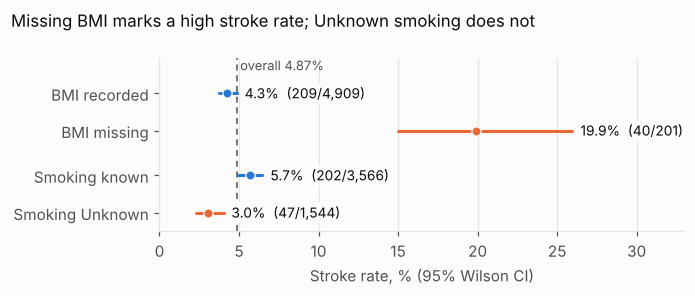

In [4]:
overall = 100 * df["stroke"].mean()
fig, ax = plt.subplots(figsize=(6.4, 2.7))
ypos = [3, 2, 0.8, -0.2]
colors = [RECORDED, MISSING, RECORDED, MISSING]
for y, c, (_, r) in zip(ypos, colors, rates.iterrows()):
    ax.plot([r.ci_low_pct, r.ci_high_pct], [y, y], color=c, lw=2, solid_capstyle="round")
    ax.plot(r.rate_pct, y, "o", ms=6, color=c, mec=SURFACE, mew=0.8, zorder=3)
    ax.text(r.ci_high_pct + 0.5, y, f"{r.rate_pct:.1f}%  ({r.strokes}/{r.n:,})", va="center", fontsize=9,
            bbox=dict(fc=SURFACE, ec="none", pad=1.5), zorder=4)
ax.axvline(overall, color=INK_2, lw=1, ls=(0, (4, 3)), zorder=1)
ax.text(overall + 0.2, 3.62, f"overall {overall:.2f}%", color=INK_2, fontsize=8.5)
ax.set_yticks(ypos, ["BMI recorded", "BMI missing", "Smoking known", "Smoking Unknown"])
ax.set_ylim(-0.7, 3.95)
ax.set_xlim(0, 33)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Stroke rate, % (95% Wilson CI)")
fig.suptitle("Missing BMI marks a high stroke rate; Unknown smoking does not", x=0.02, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "eda_stroke_rate_by_missingness.png")
plt.show()

**Reading the figure.** Patients with missing BMI had a stroke rate of 19.9% (95% CI 15.0 to 26.0), against 4.3% (3.7 to 4.9) with BMI recorded. That is a risk difference of 15.6 percentage points (10.7 to 21.7) and a risk ratio of 4.67 (3.44 to 6.36). Dropping these 201 patients would remove 40 of the 249 strokes, so complete-case analysis works on a lower-risk sample.

Patients with Unknown smoking status had a lower crude rate than patients with known status: 3.0% against 5.7%, a risk ratio of 0.54 (0.39 to 0.73). These are unadjusted rates. `02_missing_bmi.ipynb` shows that the Unknown category has an adjusted odds ratio for stroke close to 1.

## Glucose distribution (proposal Figure 1a)

Peak locations come from a Gaussian kernel density estimate. They are descriptive locations only. Fitting and testing distributions is Track 2's work (E1 to E3).

Density peaks (mg/dL): [ 83.7 207.5]
Glucose > 150 mg/dL: 730 of 5110 = 14.3% (95% Wilson CI 13.4 to 15.3)


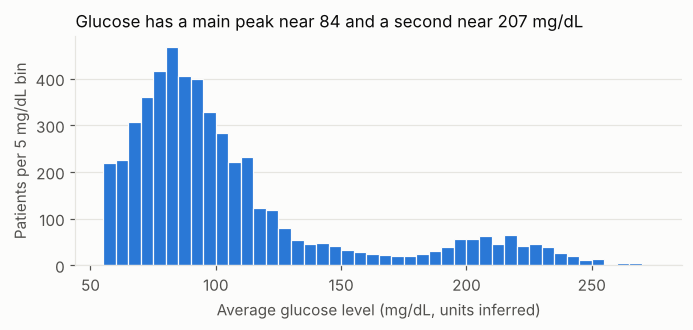

In [5]:
g = df["avg_glucose_level"]
grid = np.linspace(g.min(), g.max(), 2000)
density = stats.gaussian_kde(g)(grid)
from scipy.signal import find_peaks
peak_idx, _ = find_peaks(density, prominence=density.max() * 0.02)
peaks = grid[peak_idx]
above150 = (g > 150).sum()
lo150, hi150 = proportion_confint(above150, len(g), alpha=ALPHA, method="wilson")
print("Density peaks (mg/dL):", np.round(peaks, 1))
print(f"Glucose > 150 mg/dL: {above150} of {len(g)} = {100 * above150 / len(g):.1f}% "
      f"(95% Wilson CI {100 * lo150:.1f} to {100 * hi150:.1f})")

fig, ax = plt.subplots(figsize=(6.4, 3.1))
ax.hist(g, bins=np.arange(55, 280, 5), color=RECORDED, edgecolor=SURFACE, linewidth=0.8)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Average glucose level (mg/dL, units inferred)")
ax.set_ylabel("Patients per 5 mg/dL bin")
ax.set_title(f"Glucose has a main peak near {peaks[0]:.0f} and a second near {peaks[-1]:.0f} mg/dL")
fig.tight_layout()
fig.savefig(FIGURES / "eda_glucose_histogram.png")
plt.show()

**Reading the figure.** Glucose has a main peak near 84 mg/dL and a second, smaller peak near 207 mg/dL. This matches the proposal's description of a main group at 80 to 90 and a second group at 200 to 230 mg/dL. The second peak is the feature a single log-normal or Gamma curve will have trouble fitting. In total, 14.3% of patients (95% CI 13.4 to 15.3) have glucose above 150 mg/dL. The file does not state glucose units, so mg/dL is inferred from the range of values.

## H1. Before and after each cleaning decision

For each decision in the cleaning log (`data/README.md`) this section compares the data as analysed with the alternative we did not choose. If an estimate moves a lot, the decision matters and the report has to say so.

To make the comparisons like-for-like, every odds ratio comes from the same model: the referral model from `src/modeling.py` (age per 10 years, gender, heart disease, hypertension, glucose per 50 mg/dL, BMI per 5 kg/m², smoking status), fitted by maximum likelihood on patients with BMI recorded unless stated otherwise. Intervals are 95% Wald intervals, except the multiple-imputation row, which uses Rubin's rules (m = `N_IMPUTATIONS`). These are descriptive comparisons, not tests.

Decision 7 (combining `children` and `Never_worked` in `02_missing_bmi.ipynb`) is not repeated here; its before/after is already in the log.

In [6]:
from src.config import N_IMPUTATIONS
from src.modeling import MODEL_COLS, design, fit_sm_logit, impute_full, prepare, rubin_pool

def or_text(estimate, low, high):
    return f"{estimate:.2f} ({low:.2f} to {high:.2f})"

def complete_case_ors(data, cols=MODEL_COLS):
    """Referral model on rows with BMI recorded. Returns ORs as text, n and strokes."""
    X = design(data)
    y = data["stroke"].to_numpy()
    has_bmi = X["bmi"].notna().to_numpy()
    fit = fit_sm_logit(X[has_bmi], y[has_bmi], cols)
    ci = fit.conf_int(alpha=ALPHA)
    ors = {c: or_text(np.exp(fit.params[c]), np.exp(ci.loc[c, 0]), np.exp(ci.loc[c, 1])) for c in cols}
    return ors, int(has_bmi.sum()), int(y[has_bmi].sum())

def rows_text(data):
    return f"{len(data):,} rows, {int(data['stroke'].sum())} strokes ({100 * data['stroke'].mean():.2f}%)"

model_data = prepare(df)              # gender "Other" removed (decision 8)
base_ors, base_n, base_k = complete_case_ors(model_data)
base_fit = f"{base_n:,} patients, {base_k} strokes"
rows = []

def add(no, decision, quantity, as_analysed, alternative, alternative_is):
    rows.append({"decision": no, "short_name": decision, "quantity": quantity,
                 "as_analysed": as_analysed, "alternative": alternative, "alternative_is": alternative_is})

In [7]:
# Decision 2: keep smoking "Unknown" as its own category (alternative: drop those rows)
known = model_data[model_data["smoking_status"] != "Unknown"]
cols_known = [c for c in MODEL_COLS if c != "smoke_unknown"]
known_ors, known_n, known_k = complete_case_ors(known, cols_known)
alt = "Rows with smoking Unknown dropped"
add(2, "Smoking Unknown kept", "Rows available", rows_text(model_data), rows_text(known), alt)
add(2, "Smoking Unknown kept", "Model fitted on", base_fit, f"{known_n:,} patients, {known_k} strokes", alt)
add(2, "Smoking Unknown kept", "OR, smokes vs never", base_ors["smoke_current"], known_ors["smoke_current"], alt)
add(2, "Smoking Unknown kept", "OR, hypertension", base_ors["hypertension"], known_ors["hypertension"], alt)

# Decision 3: BMI missing handled by multiple imputation (alternative: complete case)
X_all = design(model_data)
y_all = model_data["stroke"].to_numpy()
estimates, variances = [], []
for X_imp in impute_full(model_data, m=N_IMPUTATIONS, seed=SEED):
    fit = fit_sm_logit(X_imp, y_all)
    estimates.append(fit.params.to_numpy())
    variances.append(np.diag(fit.cov_params().to_numpy()))
pooled = rubin_pool(np.array(estimates), np.array(variances))
pooled.index = ["const"] + MODEL_COLS
mi_ors = {c: or_text(*np.exp(pooled.loc[c, ["estimate", "ci_low", "ci_high"]])) for c in MODEL_COLS}
alt = "Complete case (BMI-missing rows dropped)"
add(3, "BMI missing: MI", "Model fitted on", f"{len(model_data):,} patients, {int(y_all.sum())} strokes", base_fit, alt)
add(3, "BMI missing: MI", "OR, BMI per 5 kg/m²", mi_ors["bmi"], base_ors["bmi"], alt)
add(3, "BMI missing: MI", "OR, hypertension", mi_ors["hypertension"], base_ors["hypertension"], alt)
add(3, "BMI missing: MI", "OR, age per 10 years", mi_ors["age"], base_ors["age"], alt)

# Decisions 4 and 8: gender "Other" (one record) excluded (alternative: keep it)
alt = "Record kept"
add("4, 8", "Gender Other excluded", "Rows available", rows_text(model_data), rows_text(df), alt)

# Decision 5: BMI > 60 kept (alternative: remove those rows)
bmi = df["bmi"].dropna()
no_extreme = model_data[~(model_data["bmi"] > 60)]
no_extreme_ors, no_extreme_n, _ = complete_case_ors(no_extreme)
alt = "Rows with BMI > 60 removed"
add(5, "BMI > 60 kept", "Rows with BMI > 60, strokes among them",
    f"{int((bmi > 60).sum())} rows, {int(df.loc[df['bmi'] > 60, 'stroke'].sum())} strokes", "0 rows", alt)
add(5, "BMI > 60 kept", "BMI mean (SD), kg/m²", f"{bmi.mean():.2f} ({bmi.std():.2f})",
    f"{bmi[bmi <= 60].mean():.2f} ({bmi[bmi <= 60].std():.2f})", alt)
add(5, "BMI > 60 kept", "OR, BMI per 5 kg/m²", base_ors["bmi"], no_extreme_ors["bmi"], alt)

# Decision 6: under-18s kept in the main analysis (alternative: adults only)
adults = model_data[model_data["age"] >= 18]
adult_ors, adult_n, adult_k = complete_case_ors(adults)
alt = "Adults only (age 18 and over)"
add(6, "Under-18s kept", "Rows available", rows_text(model_data), rows_text(adults), alt)
add(6, "Under-18s kept", "OR, age per 10 years", base_ors["age"], adult_ors["age"], alt)
add(6, "Under-18s kept", "OR, hypertension", base_ors["hypertension"], adult_ors["hypertension"], alt)
add(6, "Under-18s kept", "OR, BMI per 5 kg/m²", base_ors["bmi"], adult_ors["bmi"], alt)

before_after = pd.DataFrame(rows)
before_after.to_csv(TABLES / "cleaning_before_after.csv", index=False)
pd.set_option("display.max_colwidth", 60)
display(before_after)

,decision,short_name,quantity,as_analysed,alternative,alternative_is
0,2,Smoking Unknown kept,Rows available,"5,109 rows, 249 strokes (4.87%)","3,565 rows, 202 strokes (5.67%)",Rows with smoking Unknown dropped
1,2,Smoking Unknown kept,Model fitted on,"4,908 patients, 209 strokes","3,425 patients, 180 strokes",Rows with smoking Unknown dropped
2,2,Smoking Unknown kept,"OR, smokes vs never",1.46 (0.96 to 2.22),1.48 (0.97 to 2.25),Rows with smoking Unknown dropped
3,2,Smoking Unknown kept,"OR, hypertension",1.68 (1.19 to 2.36),1.76 (1.23 to 2.52),Rows with smoking Unknown dropped
4,3,BMI missing: MI,Model fitted on,"5,109 patients, 249 strokes","4,908 patients, 209 strokes",Complete case (BMI-missing rows dropped)
5,3,BMI missing: MI,"OR, BMI per 5 kg/m²",0.99 (0.89 to 1.11),1.02 (0.91 to 1.14),Complete case (BMI-missing rows dropped)
6,3,BMI missing: MI,"OR, hypertension",1.49 (1.08 to 2.06),1.68 (1.19 to 2.36),Complete case (BMI-missing rows dropped)
7,3,BMI missing: MI,"OR, age per 10 years",2.00 (1.81 to 2.22),1.99 (1.78 to 2.24),Complete case (BMI-missing rows dropped)
8,"4, 8",Gender Other excluded,Rows available,"5,109 rows, 249 strokes (4.87%)","5,110 rows, 249 strokes (4.87%)",Record kept
9,5,BMI > 60 kept,"Rows with BMI > 60, strokes among them","13 rows, 0 strokes",0 rows,Rows with BMI > 60 removed


**Result: no cleaning decision changes a conclusion.**

- **Smoking Unknown kept (decision 2).** Dropping the 1,544 Unknown rows would lose 47 of the 249 strokes. The odds ratios barely move: current smoking 1.46 (0.96 to 2.22) kept against 1.48 (0.97 to 2.25) dropped, and hypertension 1.68 against 1.76, with overlapping intervals.
- **BMI missing handled by multiple imputation (decision 3).** Complete case loses 201 patients and 40 strokes (16% of all strokes). The odds ratios are close: BMI 0.99 (MI) against 1.02 (complete case), hypertension 1.49 against 1.68, age 2.00 against 1.99. The hypertension estimate is the one that moves most, and both intervals overlap widely. `02_missing_bmi.ipynb` (D3, D4) and `06_model.ipynb` (B3) give the full comparison.
- **Gender Other excluded (decisions 4 and 8).** One record without a stroke, so the stroke rate is 4.87% either way.
- **BMI > 60 kept (decision 5).** The 13 rows have no strokes. Removing them lowers mean BMI from 28.89 to 28.79 kg/m² and changes the BMI odds ratio from 1.02 to 1.03; both intervals include 1.
- **Under-18s kept (decision 6).** Removing the 856 children and adolescents (2 strokes) raises the stroke rate from 4.87% to 5.81%. In the model the age and hypertension odds ratios are unchanged to two decimals, and the BMI odds ratio moves from 1.02 to 1.01. The adults-only sensitivity analysis of the referral model's performance is Track 4's G5.